# 05 - Engineered labels: a built-in quantum advantage (week 2)
Owner: **Haider**

On the real T-shirt/Shirt labels the projected kernel loses to the best classical model (notebook 04). Is that because there is no advantage to find, or because our pipeline cannot detect one? This notebook is the **positive control**.

Following Huang et al. (Sec. 3), we keep the **same images** and replace the labels with ones built to suit the quantum kernel: the direction where the quantum and classical kernels differ most,

$$y = \sqrt{K^Q}\,v,\qquad v = \text{top eigenvector of } \sqrt{K^Q}\sqrt{K^C}\,(K^C+\lambda I)^{-2}\sqrt{K^C}\sqrt{K^Q},$$

split at the median into two balanced classes.

- **Generator (fixed in advance):** $K^Q$ = ideal projected kernel ($L=2$, $\alpha=1$, $\gamma$ scale 2); $K^C$ = sum of all 9 classical kernel settings in the tuning grids, so the labels are hard for the whole classical search space; $\lambda \in \{0.1, 0.01, 0.001\}$, all reported.
- **Models:** trained exactly as before: same split, PCA on training images only, same 28-setting budget, inner CV for tuning, one test score.
- **Expectation:** if the pipeline works, $\Delta A = A^Q - A^{C^\ast}$ should now be positive.

In [1]:
import sys, json, time
sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
from src.common import (get_split, make_preprocessor, encoding_circuit, inner_folds,
                        result_path, RESULTS, SEEDS)
from src.baselines import run_baselines, best_classical, classical_gram
from src.projected import tune_projected
from src.geometry import geometric_difference
from src.engineered import generator_kernels, engineered_labels, GEN_LAMBDAS

## 1. Settings

In [2]:
N_LIST = [2, 4, 6, 8]
LAYERS = 2
KINDS = {"SVM RBF (tuned)": "rbf", "SVM polynomial (tuned)": "poly", "SVM linear (tuned)": "linear"}
lam_tag = lambda lam: f"{lam:g}".replace(".", "p")      # 0.01 -> "0p01" for file names
print("generator lambdas:", GEN_LAMBDAS)

generator lambdas: (0.1, 0.01, 0.001)


## 2. Generate labels, then train and test every model

In [3]:
eng_runs = []
t0 = time.time()
for n in N_LIST:
    enc = encoding_circuit(n, LAYERS)
    for seed in SEEDS:
        Xtr, ytr0, Xte, yte0 = get_split(seed)
        KC_gen, KQ_gen = generator_kernels(np.vstack([Xtr, Xte]), n)   # labelling step only
        tf = make_preprocessor(n, alpha=1.0)(Xtr)                       # same features as notebook 01
        Ftr, Fte = tf(Xtr), tf(Xte)
        for lam in GEN_LAMBDAS:
            lab, gen = engineered_labels(KC_gen, KQ_gen, lam)
            ytr, yte = lab[:len(ytr0)], lab[len(ytr0):]
            folds = inner_folds(ytr, seed)
            base = run_baselines(Ftr, ytr, Fte, yte, folds)
            c_star = best_classical(base)
            proj, K_e, _ = tune_projected(enc, make_preprocessor, Xtr, ytr, Xte, yte, folds, seed)
            KC_star = classical_gram(KINDS[c_star], base[c_star]["params"], Ftr)
            out = dict(seed=seed, n_qubits=n, lam=lam, generator=gen,
                       train_pos=int((ytr == 1).sum()), test_pos=int((yte == 1).sum()),
                       agree_with_original=float(np.mean(lab == np.r_[ytr0, yte0])),
                       baselines=base, c_star=c_star, acc_c_star=base[c_star]["acc"],
                       projected=proj, delta_A=proj["sampled"]["acc"] - base[c_star]["acc"],
                       g_c_star=geometric_difference(KC_star, K_e)[0])
            result_path("tables", f"engineered_lam{lam_tag(lam)}", seed, n, "json").write_text(
                json.dumps(out, indent=2, default=str))
            eng_runs.append(out)
    print(f"n={n}: done ({time.time() - t0:.0f} s so far)")

n=2: done (124 s so far)
n=4: done (272 s so far)
n=6: done (439 s so far)
n=8: done (614 s so far)


## 3. Results

In [4]:
def ms(v):
    v = np.asarray(v, float)
    return f"{v.mean():>8.3f} +-{v.std():.3f}"

for lam in GEN_LAMBDAS:
    rows = [r for r in eng_runs if r["lam"] == lam]
    print(f"=== engineered labels, lambda = {lam:g}: test accuracy, mean +- std over {len(SEEDS)} seeds ===")
    print(f"{'':<24}" + "".join(f"{'n=' + str(n):>16}" for n in N_LIST))
    table = [("Logistic regression", lambda r: r["baselines"]["Logistic regression"]["acc"]),
             ("best classical C*", lambda r: r["acc_c_star"]),
             ("projected (sampled)", lambda r: r["projected"]["sampled"]["acc"]),
             ("projected (exact)", lambda r: r["projected"]["exact"]["acc"]),
             ("Delta A", lambda r: r["delta_A"]),
             ("g_gen generator pair", lambda r: r["generator"]["g_gen"]),
             ("agree w/ real labels", lambda r: r["agree_with_original"])]
    for label, f in table:
        print(f"{label:<24}" + "".join(f"{ms([f(r) for r in rows if r['n_qubits'] == n]):>16}" for n in N_LIST))
    verdict = []
    for n in N_LIST:
        d = np.array([r["delta_A"] for r in rows if r["n_qubits"] == n])
        verdict.append(f"n={n}: {'improvement' if d.mean() > d.std() else 'no improvement'}")
    print("falsifier (mean Delta A > std):", ", ".join(verdict))
    bal = [(r["train_pos"], r["test_pos"]) for r in rows]
    print(f"class +1 count: train {min(b[0] for b in bal)}-{max(b[0] for b in bal)} of 80, "
          f"test {min(b[1] for b in bal)}-{max(b[1] for b in bal)} of 40\n")

=== engineered labels, lambda = 0.1: test accuracy, mean +- std over 5 seeds ===
                                     n=2             n=4             n=6             n=8
Logistic regression        0.770 +-0.147   0.700 +-0.131   0.605 +-0.122   0.660 +-0.073
best classical C*          0.940 +-0.030   0.845 +-0.040   0.775 +-0.069   0.770 +-0.125
projected (sampled)        0.905 +-0.097   0.855 +-0.073   0.825 +-0.061   0.825 +-0.059
projected (exact)          0.915 +-0.087   0.850 +-0.089   0.820 +-0.056   0.840 +-0.070
Delta A                   -0.035 +-0.072   0.010 +-0.041   0.050 +-0.035   0.055 +-0.086
g_gen generator pair       2.661 +-0.108   3.044 +-0.141   2.957 +-0.149   3.060 +-0.206
agree w/ real labels       0.417 +-0.136   0.537 +-0.039   0.503 +-0.053   0.500 +-0.051
falsifier (mean Delta A > std): n=2: no improvement, n=4: no improvement, n=6: improvement, n=8: no improvement
class +1 count: train 36-44 of 80, test 16-24 of 40

=== engineered labels, lambda = 0.01: test

**Reading the table:** "agree w/ real labels" near 0.5 means the engineered labels have nothing to do with T-shirt vs Shirt; they are a new task on the same images. The falsifier is the same rule as on the real labels: an improvement only if mean $\Delta A$ exceeds its standard deviation.

## 4. Figures: best classical vs best quantum, real vs engineered labels

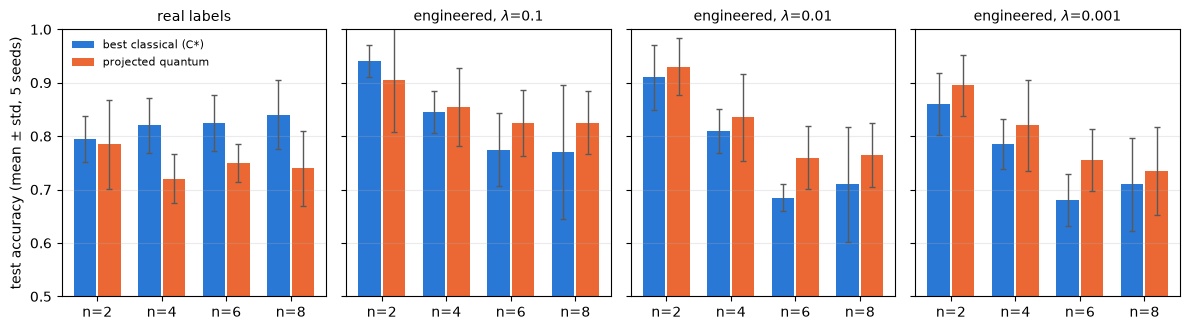

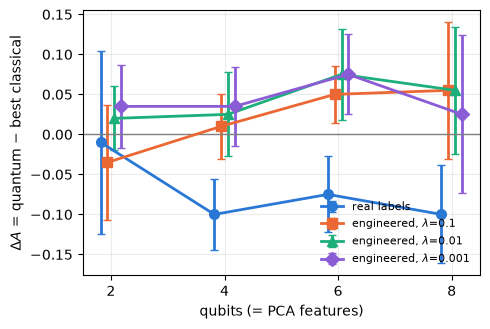

saved figures to E:\LUMS\Semester 3\Quantum Machine Learning\Project\AI631-Projected-Quantum-Kernels\results\figures


In [5]:
figdir = RESULTS / "figures"
figdir.mkdir(parents=True, exist_ok=True)

# real-label results from notebooks 01 and 03
real = []
for n in N_LIST:
    for seed in SEEDS:
        b = json.loads(result_path("tables", "baselines_v2", seed, n, "json").read_text())
        p = json.loads(result_path("tables", "projected_v2", seed, n, "json").read_text())
        real.append(dict(n_qubits=n, acc_c_star=b["results"][b["c_star"]]["acc"],
                         acc_q=p["sampled"]["acc"]))

panels = [("real labels", real, lambda r: r["acc_q"])] + [
    (f"engineered, $\\lambda$={lam:g}", [r for r in eng_runs if r["lam"] == lam],
     lambda r: r["projected"]["sampled"]["acc"]) for lam in GEN_LAMBDAS]

x, w = np.arange(len(N_LIST)), 0.38
fig, axes = plt.subplots(1, len(panels), figsize=(12, 3.4), sharey=True)
for ax, (title, rows, qacc) in zip(axes, panels):
    for k, (lab, f, col) in enumerate([("best classical (C*)", lambda r: r["acc_c_star"], "#2a78d6"),
                                       ("projected quantum", qacc, "#eb6834")]):
        m = [np.mean([f(r) for r in rows if r["n_qubits"] == n]) for n in N_LIST]
        s = [np.std([f(r) for r in rows if r["n_qubits"] == n]) for n in N_LIST]
        ax.bar(x + (k - 0.5) * w, m, w * 0.92, yerr=s, color=col, capsize=2,
               error_kw=dict(elinewidth=1, ecolor="0.35"), label=lab)
    ax.set_title(title, fontsize=10)
    ax.set_xticks(x, [f"n={n}" for n in N_LIST])
    ax.set_ylim(0.5, 1.0)
    ax.grid(axis="y", alpha=0.25)
axes[0].set_ylabel("test accuracy (mean $\\pm$ std, 5 seeds)")
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig(figdir / "best_classical_vs_quantum.png", dpi=200)
plt.show()

fig, ax = plt.subplots(figsize=(5, 3.4))
series = [("real labels", real, lambda r: r["acc_q"] - r["acc_c_star"], "#2a78d6", "o")]
series += [(f"engineered, $\\lambda$={lam:g}", [r for r in eng_runs if r["lam"] == lam],
            lambda r: r["delta_A"], c, mk)
           for lam, c, mk in zip(GEN_LAMBDAS, ["#eb6834", "#1baf7a", "#8a5cd6"], ["s", "^", "D"])]
for k, (lab, rows, f, c, mk) in enumerate(series):
    m = [np.mean([f(r) for r in rows if r["n_qubits"] == n]) for n in N_LIST]
    s = [np.std([f(r) for r in rows if r["n_qubits"] == n]) for n in N_LIST]
    ax.errorbar(np.array(N_LIST) + (k - 1.5) * 0.12, m, yerr=s, color=c, marker=mk,
                markersize=7, linewidth=2, capsize=3, label=lab)
ax.axhline(0, color="0.5", linewidth=1)
ax.set_xticks(N_LIST)
ax.set_xlabel("qubits (= PCA features)")
ax.set_ylabel(r"$\Delta A$ = quantum $-$ best classical")
ax.grid(alpha=0.25)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(figdir / "deltaA_real_vs_engineered.png", dpi=200)
plt.show()
print("saved figures to", figdir)

## 5. Fidelity kernel on the engineered labels (reuses notebook 02's saved kernels)

In [6]:
from src.common import cv_score_precomputed, evaluate_precomputed

FID_ALPHAS = [0.5, 1.0, 2.0, np.pi]                 # same 28-setting budget as notebook 02
CS = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
a_tag = lambda a: f"{a:.3f}".replace(".", "p")      # same file names as notebook 02

fid_eng = []
for n in N_LIST:
    for seed in SEEDS:
        Xtr, ytr0, Xte, yte0 = get_split(seed)
        KC_gen, KQ_gen = generator_kernels(np.vstack([Xtr, Xte]), n)   # same labels as section 2
        kers = {a: (np.load(result_path("kernels", f"fidelity_sampled_train_a{a_tag(a)}", seed, n, "npy")),
                    np.load(result_path("kernels", f"fidelity_sampled_test_a{a_tag(a)}", seed, n, "npy")))
                for a in FID_ALPHAS}
        for lam in GEN_LAMBDAS:
            lab, _ = engineered_labels(KC_gen, KQ_gen, lam)
            ytr, yte = lab[:len(ytr0)], lab[len(ytr0):]
            p = result_path("tables", f"engineered_lam{lam_tag(lam)}", seed, n, "json")
            out = json.loads(p.read_text())
            assert out["train_pos"] == int((ytr == 1).sum()), "labels differ from section 2"
            folds = inner_folds(ytr, seed)
            best = dict(score=-1)
            for a, (K, Kt) in kers.items():
                for C in CS:
                    s = cv_score_precomputed(K, ytr, folds, C)
                    if s > best["score"]:
                        best = dict(score=s, alpha=a, C=C)
            K, Kt = kers[best["alpha"]]
            res = evaluate_precomputed(K, Kt, ytr, yte, best["C"])
            out["fidelity"] = dict(best=best, sampled=res)
            out["delta_A_fidelity"] = res["acc"] - out["acc_c_star"]
            p.write_text(json.dumps(out, indent=2, default=str))
            fid_eng.append(out)
    print(f"n={n}: done")

for lam in GEN_LAMBDAS:
    rows = [r for r in fid_eng if r["lam"] == lam]
    print(f"\n=== engineered labels, lambda = {lam:g}: test accuracy, mean +- std over {len(SEEDS)} seeds ===")
    print(f"{'':<24}" + "".join(f"{'n=' + str(n):>16}" for n in N_LIST))
    for label, f in [("best classical C*", lambda r: r["acc_c_star"]),
                     ("projected (sampled)", lambda r: r["projected"]["sampled"]["acc"]),
                     ("fidelity (sampled)", lambda r: r["fidelity"]["sampled"]["acc"]),
                     ("Delta A projected", lambda r: r["delta_A"]),
                     ("Delta A fidelity", lambda r: r["delta_A_fidelity"])]:
        vals = [np.array([f(r) for r in rows if r["n_qubits"] == n]) for n in N_LIST]
        print(f"{label:<24}" + "".join(f"{v.mean():>8.3f} +-{v.std():.3f}" for v in vals))
    verdict = []
    for n in N_LIST:
        d = np.array([r["delta_A_fidelity"] for r in rows if r["n_qubits"] == n])
        verdict.append(f"n={n}: {'improvement' if d.mean() > d.std() else 'no improvement'}")
    print("fidelity falsifier (mean Delta A > std):", ", ".join(verdict))

n=2: done
n=4: done
n=6: done
n=8: done

=== engineered labels, lambda = 0.1: test accuracy, mean +- std over 5 seeds ===
                                     n=2             n=4             n=6             n=8
best classical C*          0.940 +-0.030   0.845 +-0.040   0.775 +-0.069   0.770 +-0.125
projected (sampled)        0.905 +-0.097   0.855 +-0.073   0.825 +-0.061   0.825 +-0.059
fidelity (sampled)         0.905 +-0.100   0.830 +-0.056   0.710 +-0.083   0.770 +-0.053
Delta A projected         -0.035 +-0.072   0.010 +-0.041   0.050 +-0.035   0.055 +-0.086
Delta A fidelity          -0.035 +-0.075  -0.015 +-0.025  -0.065 +-0.060   0.000 +-0.079
fidelity falsifier (mean Delta A > std): n=2: no improvement, n=4: no improvement, n=6: no improvement, n=8: no improvement

=== engineered labels, lambda = 0.01: test accuracy, mean +- std over 5 seeds ===
                                     n=2             n=4             n=6             n=8
best classical C*          0.910 +-0.060   0.810